# Results — MDS

**Este notebook NO entrena / NO resuelve el problema.**

Lee los JSON en `Notebooks/Optimization/MinimumDominatingSetOptimization/metrics/` y crea las figuras
para el documento y la defensa.

Solvers esperados: brute force, greedy, ILP, QUBO+SA, QAOA, VQE.


## Cargar métricas


In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def resolve_optimization_dir() -> Path:
    for base in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        root = base / "Notebooks" / "Optimization"
        if root.is_dir():
            return root
    return Path.cwd().resolve() / "Notebooks" / "Optimization"


OPT_ROOT = resolve_optimization_dir()
CASE_DIR = OPT_ROOT / "MinimumDominatingSetOptimization"
RESULTS_DIR = OPT_ROOT / "ResultsOptimization"
METRICS_DIR = CASE_DIR / "metrics"       # JSON de solvers (entrada)
FIGURES_DIR = RESULTS_DIR / "figures"    # figuras de resultados
SUMMARY_DIR = RESULTS_DIR / "metrics"    # CSV resumen
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
SUMMARY_DIR.mkdir(parents=True, exist_ok=True)
EXPECTED = {
    "brute_force": "bruteforce_mds.json",
    "greedy": "greedy_mds.json",
    "ilp": "ilp_mds.json",
    "simulated_annealing": "sa_mds.json",
    "qaoa": "qaoa_mds.json",
    "vqe": "vqe_mds.json"
}
ALL_SOLVERS = list(EXPECTED.keys())

results = {}
missing = []
for solver, filename in EXPECTED.items():
    path = METRICS_DIR / filename
    if not path.exists():
        missing.append(str(path))
        continue
    results[solver] = json.loads(path.read_text())

if missing:
    raise FileNotFoundError(
        "Faltan métricas. Ejecuta antes los notebooks de este directorio.\n"
        + "\n".join(f" - {m}" for m in missing)
    )

print(f"Loaded {len(results)}/{len(EXPECTED)} from {METRICS_DIR}")
for s in ALL_SOLVERS:
    r = results[s]
    print(
        f"  {s}: success={r['success_rate']:.3f} | "
        f"cost_mean={r['quality'].get('cost_mean')} | "
        f"gap_mean={r['quality'].get('gap_mean')} | "
        f"time_mean={r['time_s']['mean']:.4f}s"
    )


## Tabla consolidada


In [2]:
rows = []
for solver in ALL_SOLVERS:
    r = results[solver]
    q = r["quality"]
    rows.append({
        "solver": solver,
        "display": DISPLAY_NAME.get(solver, solver) if "DISPLAY_NAME" in globals() else solver,
        "family": r.get("family", "classical"),
        "success_rate": r["success_rate"],
        "cost_mean": q.get("cost_mean"),
        "cost_best": q.get("cost_best"),
        "gap_mean": q.get("gap_mean"),
        "optimal_cost": q.get("optimal_cost"),
        "time_mean_s": r["time_s"]["mean"],
        "time_std_s": r["time_s"].get("std"),
        "energy_evals_mean": r.get("effort", {}).get("energy_evals_mean"),
    })

df = pd.DataFrame(rows).set_index("solver").loc[ALL_SOLVERS].reset_index()


## Estilo y paleta

Clásico = azules oscuros / gris; quantum-inspired = azules claros.


In [ ]:

CLASSICAL_SOLVERS = ["brute_force", "greedy", "ilp", "simulated_annealing"]
QUANTUM_SOLVERS = ["qaoa", "vqe"]

SOLVER_COLORS = {
    "brute_force": "#0B1F33",
    "greedy": "#0E4A75",
    "ilp": "#4A5560",
    "simulated_annealing": "#219BC3",
    "qaoa": "#7EC8E3",
    "vqe": "#A8D5E5",
}
FAMILY_COLORS = {"classical": "#0E4A75", "quantum_inspired": "#A8D5E5"}

UNIR_NAVY = "#0E4A75"
UNIR_GRIS = "#858591"
UNIR_CLARO = "#C0C0C8"

plt.rcParams.update({
    "font.sans-serif": ["Arial", "DejaVu Sans", "Helvetica"],
    "axes.edgecolor": UNIR_CLARO,
    "grid.color": UNIR_CLARO,
    "grid.linestyle": "--",
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "figure.dpi": 150,
    "legend.fontsize": 9,
})

DISPLAY_NAME = {
    "brute_force": "Brute force",
    "greedy": "Greedy",
    "ilp": "ILP",
    "simulated_annealing": "QUBO + SA",
    "qaoa": "QAOA",
    "vqe": "VQE",
}

def savefig(name):
    path = FIGURES_DIR / name
    plt.savefig(path, bbox_inches="tight", facecolor="white")
    print("Saved:", path)
    plt.show()

def annotate_bars(ax, container, fmt="{:.2f}", dy=None, fontsize=8):
    for bar in container:
        h = bar.get_height()
        if np.isnan(h):
            continue
        offset = (0.02 * max(ax.get_ylim()[1], 1)) if dy is None else dy
        ax.text(bar.get_x() + bar.get_width()/2, h + offset, fmt.format(h),
                ha="center", va="bottom", fontsize=fontsize, color=UNIR_GRIS)

# patch display names into df now that DISPLAY_NAME exists
df["display"] = [DISPLAY_NAME[s] for s in df["solver"]]
print(df.round(4).to_string(index=False))
summary_path = SUMMARY_DIR / "mds_optimization_summary.csv"
df.to_csv(summary_path, index=False)
print("\nSaved:", summary_path)


### 1. Success rate


Saved: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/MinimumDominatingSetOptimization/figures/mds_success_rate.png


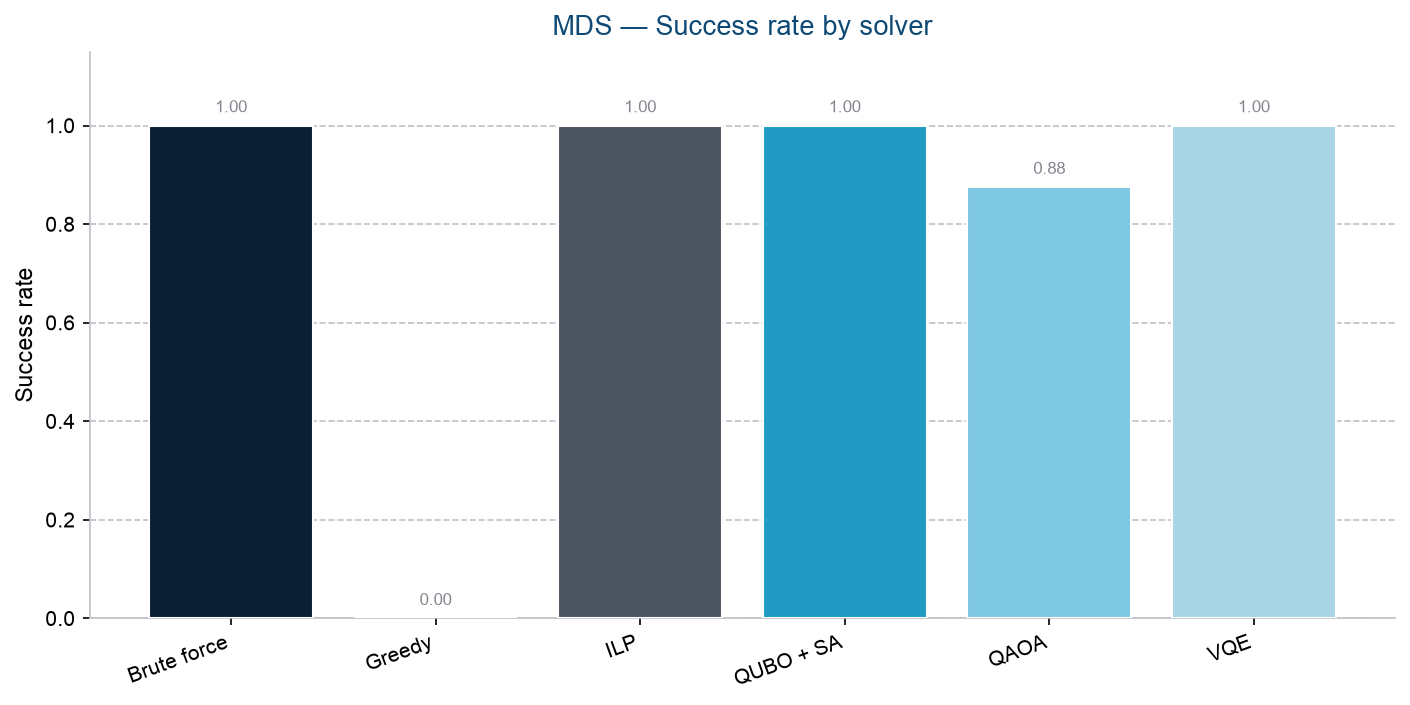

In [4]:
fig, ax = plt.subplots(figsize=(9.5, 4.8))
x = np.arange(len(ALL_SOLVERS))
colors = [SOLVER_COLORS[s] for s in ALL_SOLVERS]
bars = ax.bar(x, df["success_rate"], color=colors, edgecolor="white", zorder=3)
annotate_bars(ax, bars, fmt="{:.2f}", dy=0.02)
ax.set_xticks(x)
ax.set_xticklabels([DISPLAY_NAME[s] for s in ALL_SOLVERS], rotation=20, ha="right")
ax.set_ylim(0, 1.15)
ax.set_ylabel("Success rate")
ax.set_title("MDS — Success rate by solver", color=UNIR_NAVY, pad=8)
ax.grid(axis="y", zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
savefig("mds_success_rate.png")


### 2. Coste medio vs óptimo


Saved: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/MinimumDominatingSetOptimization/figures/mds_cost_mean.png


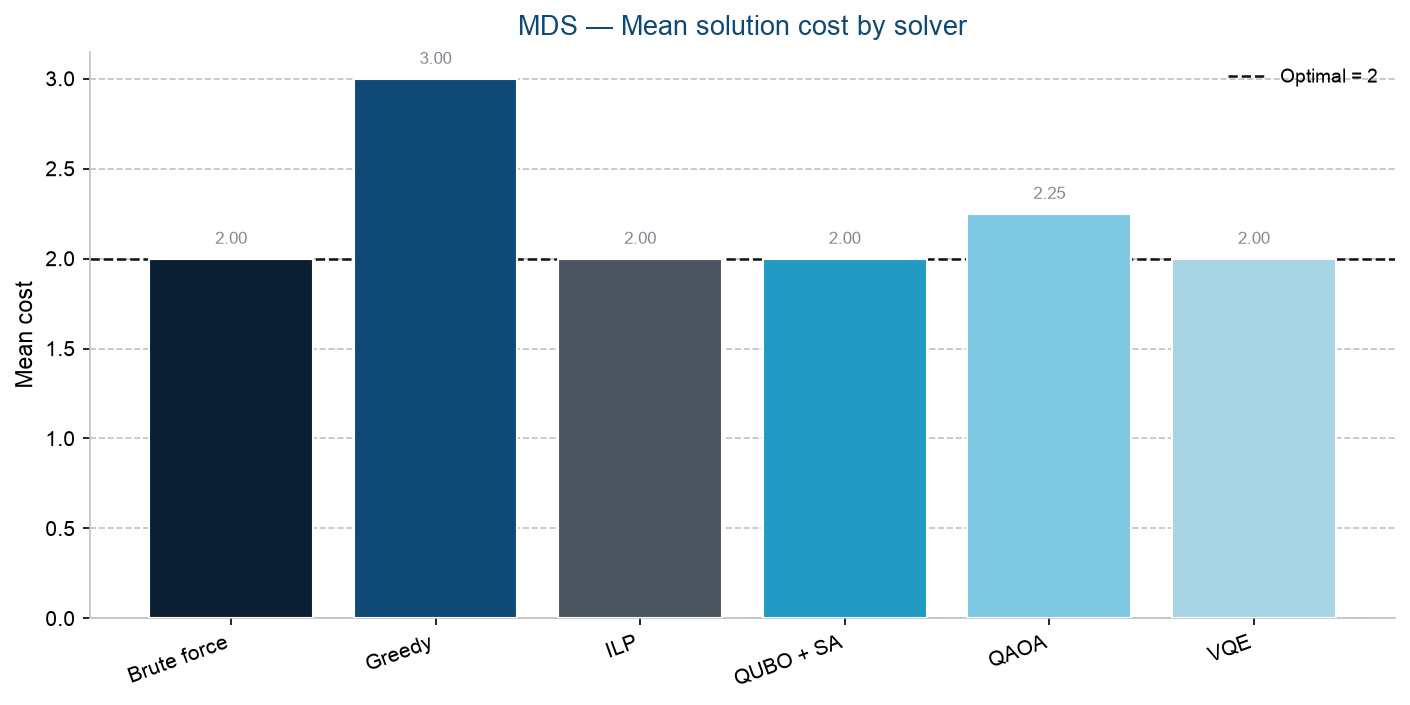

In [5]:
fig, ax = plt.subplots(figsize=(9.5, 4.8))
bars = ax.bar(x, df["cost_mean"], color=colors, edgecolor="white", zorder=3)
opt = float(df["optimal_cost"].iloc[0])
ax.axhline(opt, color="#111111", lw=1.2, ls="--", label=f"Optimal = {opt:g}")
annotate_bars(ax, bars, fmt="{:.2f}")
ax.set_xticks(x)
ax.set_xticklabels([DISPLAY_NAME[s] for s in ALL_SOLVERS], rotation=20, ha="right")
ax.set_ylabel("Mean cost")
ax.set_title("MDS — Mean solution cost by solver", color=UNIR_NAVY, pad=8)
ax.legend(frameon=False, loc="best")
ax.grid(axis="y", zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
savefig("mds_cost_mean.png")


### 3. Gap de optimalidad


Saved: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/MinimumDominatingSetOptimization/figures/mds_gap.png


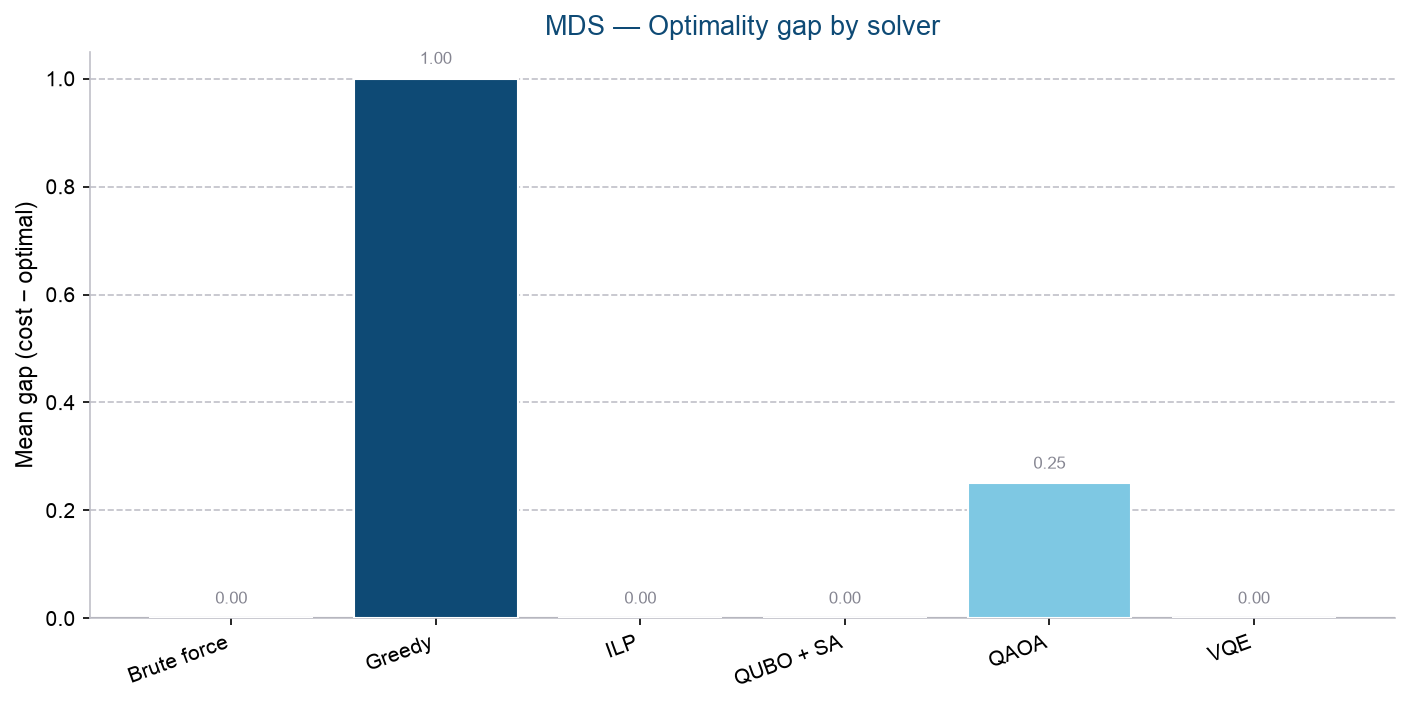

In [6]:
fig, ax = plt.subplots(figsize=(9.5, 4.8))
bars = ax.bar(x, df["gap_mean"], color=colors, edgecolor="white", zorder=3)
annotate_bars(ax, bars, fmt="{:.2f}")
ax.axhline(0, color=UNIR_GRIS, lw=1)
ax.set_xticks(x)
ax.set_xticklabels([DISPLAY_NAME[s] for s in ALL_SOLVERS], rotation=20, ha="right")
ax.set_ylabel("Mean gap (cost − optimal)")
ax.set_title("MDS — Optimality gap by solver", color=UNIR_NAVY, pad=8)
ax.grid(axis="y", zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
savefig("mds_gap.png")


### 4. Tiempo de ejecución


Saved: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/MinimumDominatingSetOptimization/figures/mds_runtime.png


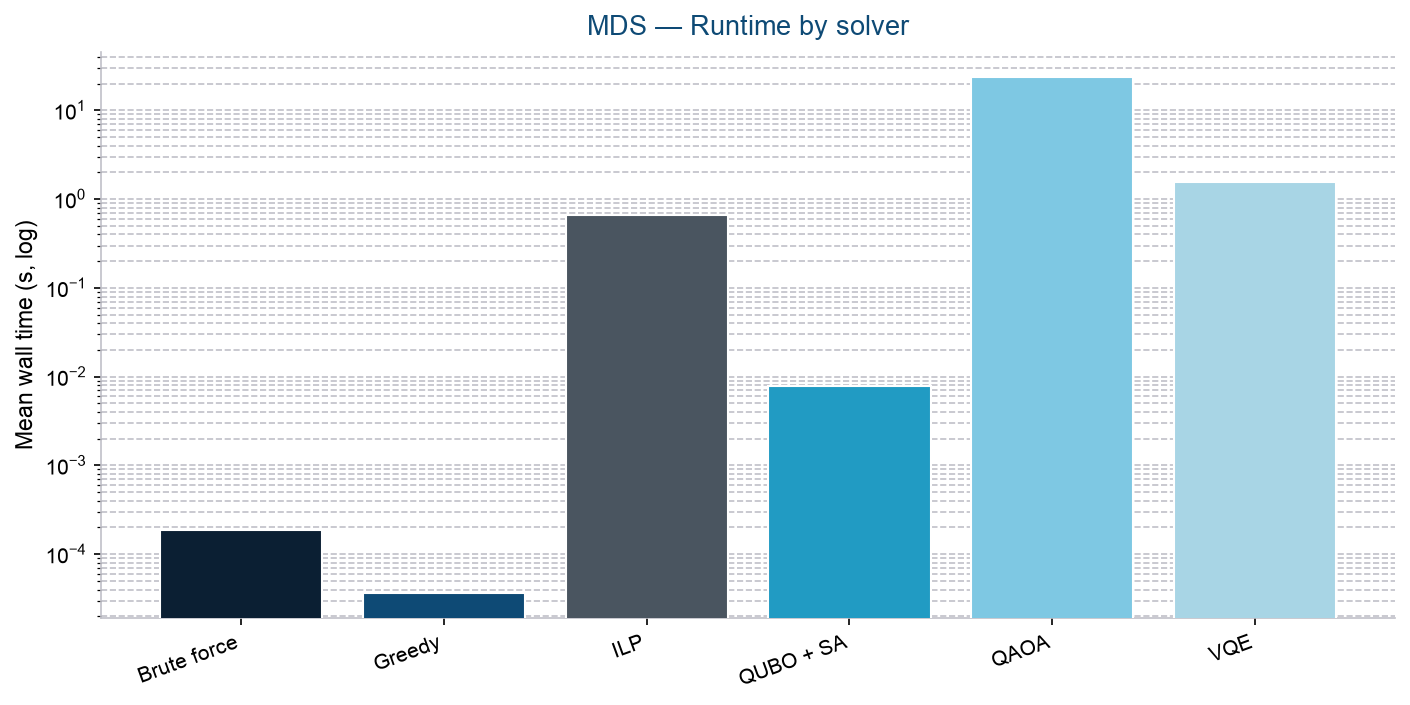

In [7]:
fig, ax = plt.subplots(figsize=(9.5, 4.8))
bars = ax.bar(x, df["time_mean_s"].clip(lower=1e-6), color=colors, edgecolor="white", zorder=3)
ax.set_yscale("log")
ax.set_xticks(x)
ax.set_xticklabels([DISPLAY_NAME[s] for s in ALL_SOLVERS], rotation=20, ha="right")
ax.set_ylabel("Mean wall time (s, log)")
ax.set_title("MDS — Runtime by solver", color=UNIR_NAVY, pad=8)
ax.grid(axis="y", zorder=0, which="both")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
savefig("mds_runtime.png")


### 5. Clásicos vs quantum-inspired

Dos paneles (ejes distintos): **success rate** y **gap de optimalidad**.


Saved: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/MinimumDominatingSetOptimization/figures/mds_classical_vs_quantum.png


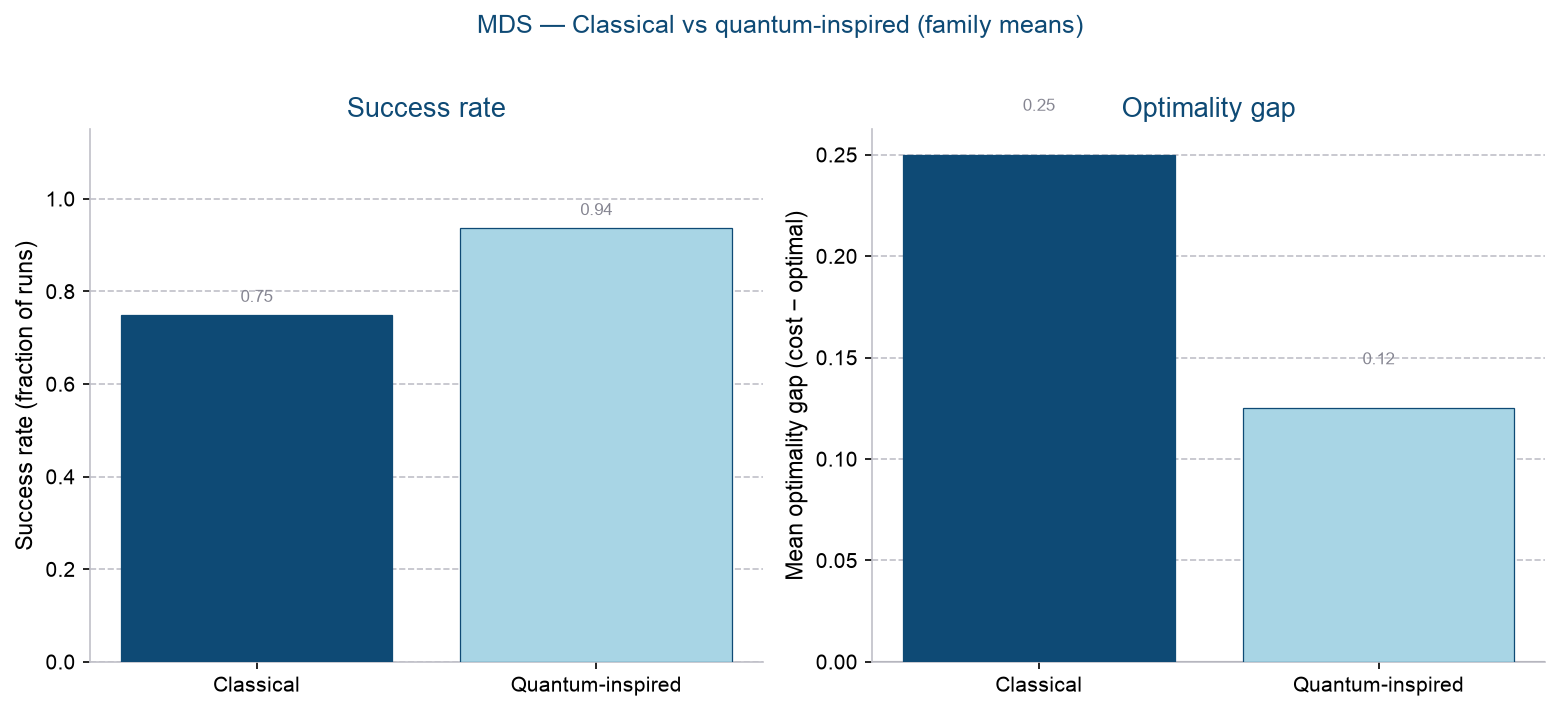

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(10.5, 4.6))
classic = df[df["family"] == "classical"]
quantum = df[df["family"] == "quantum_inspired"]

# Panel A: success rate
vals_s = [classic["success_rate"].mean(), quantum["success_rate"].mean()]
b1 = axs[0].bar(["Classical", "Quantum-inspired"], vals_s,
                color=[FAMILY_COLORS["classical"], FAMILY_COLORS["quantum_inspired"]],
                edgecolor="#0E4A75", linewidth=0.6, zorder=3)
annotate_bars(axs[0], b1, fmt="{:.2f}", dy=0.02)
axs[0].set_ylim(0, 1.15)
axs[0].set_ylabel("Success rate (fraction of runs)")
axs[0].set_title("Success rate", color=UNIR_NAVY)
axs[0].grid(axis="y", zorder=0)
axs[0].spines["top"].set_visible(False)
axs[0].spines["right"].set_visible(False)

# Panel B: optimality gap
vals_g = [classic["gap_mean"].mean(), quantum["gap_mean"].mean()]
b2 = axs[1].bar(["Classical", "Quantum-inspired"], vals_g,
                color=[FAMILY_COLORS["classical"], FAMILY_COLORS["quantum_inspired"]],
                edgecolor="#0E4A75", linewidth=0.6, zorder=3)
annotate_bars(axs[1], b2, fmt="{:.2f}")
axs[1].axhline(0, color=UNIR_GRIS, lw=1)
axs[1].set_ylabel("Mean optimality gap (cost − optimal)")
axs[1].set_title("Optimality gap", color=UNIR_NAVY)
axs[1].grid(axis="y", zorder=0)
axs[1].spines["top"].set_visible(False)
axs[1].spines["right"].set_visible(False)

fig.suptitle("MDS — Classical vs quantum-inspired (family means)", color=UNIR_NAVY, y=1.02)
fig.tight_layout()
savefig("mds_classical_vs_quantum.png")


### 6. Success vs runtime


Saved: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/MinimumDominatingSetOptimization/figures/mds_success_vs_runtime.png


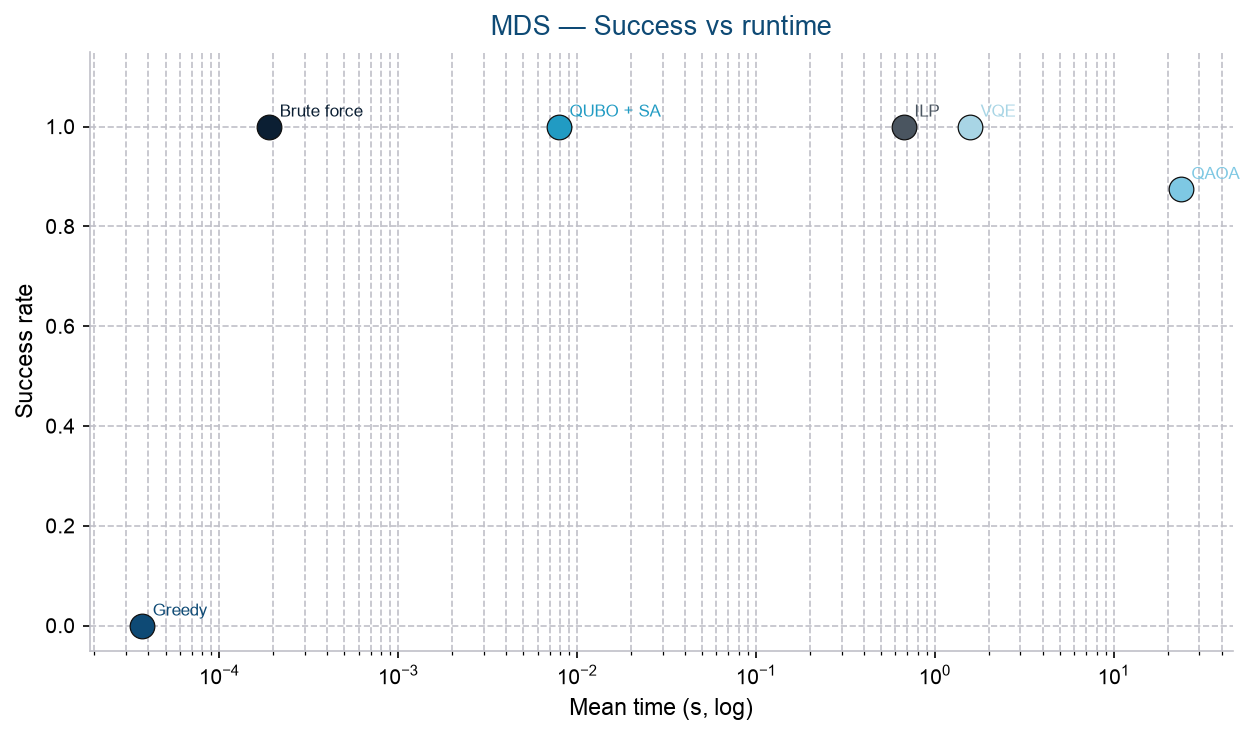

In [9]:
fig, ax = plt.subplots(figsize=(8.5, 5))
for _, row in df.iterrows():
    t = max(float(row["time_mean_s"]), 1e-6)
    ax.scatter(t, row["success_rate"], s=140, color=SOLVER_COLORS[row["solver"]],
               edgecolor="#111111", linewidth=0.6, zorder=3)
    ax.text(t * 1.15, row["success_rate"] + 0.02, row["display"], fontsize=8,
            color=SOLVER_COLORS[row["solver"]])
ax.set_xscale("log")
ax.set_xlabel("Mean time (s, log)")
ax.set_ylabel("Success rate")
ax.set_ylim(-0.05, 1.15)
ax.set_title("MDS — Success vs runtime", color=UNIR_NAVY, pad=8)
ax.grid(True, which="both", zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
savefig("mds_success_vs_runtime.png")


### 7. Gap vs runtime


Saved: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/MinimumDominatingSetOptimization/figures/mds_gap_vs_runtime.png


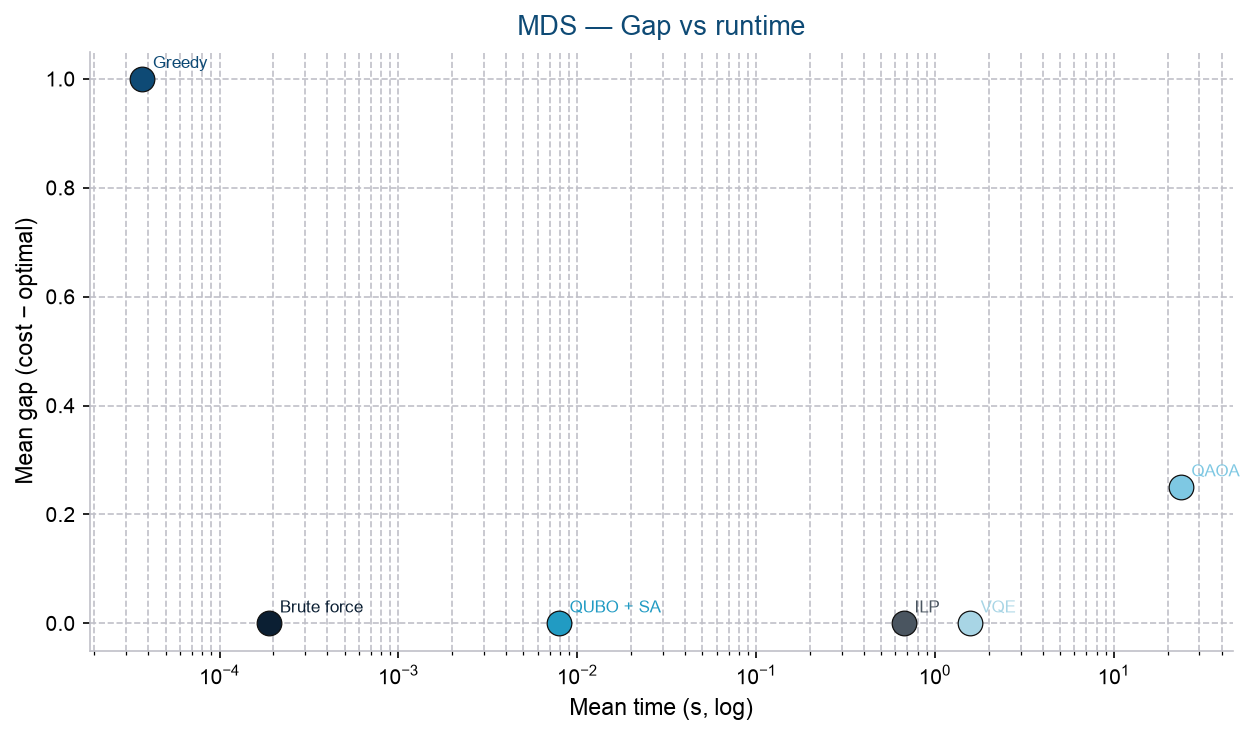

In [10]:
fig, ax = plt.subplots(figsize=(8.5, 5))
for _, row in df.iterrows():
    t = max(float(row["time_mean_s"]), 1e-6)
    ax.scatter(t, row["gap_mean"], s=140, color=SOLVER_COLORS[row["solver"]],
               edgecolor="#111111", linewidth=0.6, zorder=3)
    ax.text(t * 1.15, float(row["gap_mean"]) + 0.02, row["display"], fontsize=8,
            color=SOLVER_COLORS[row["solver"]])
ax.set_xscale("log")
ax.set_xlabel("Mean time (s, log)")
ax.set_ylabel("Mean gap (cost − optimal)")
ax.set_title("MDS — Gap vs runtime", color=UNIR_NAVY, pad=8)
ax.grid(True, which="both", zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
savefig("mds_gap_vs_runtime.png")


### 8. Heatmap resumen


Saved: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/MinimumDominatingSetOptimization/figures/mds_heatmap.png


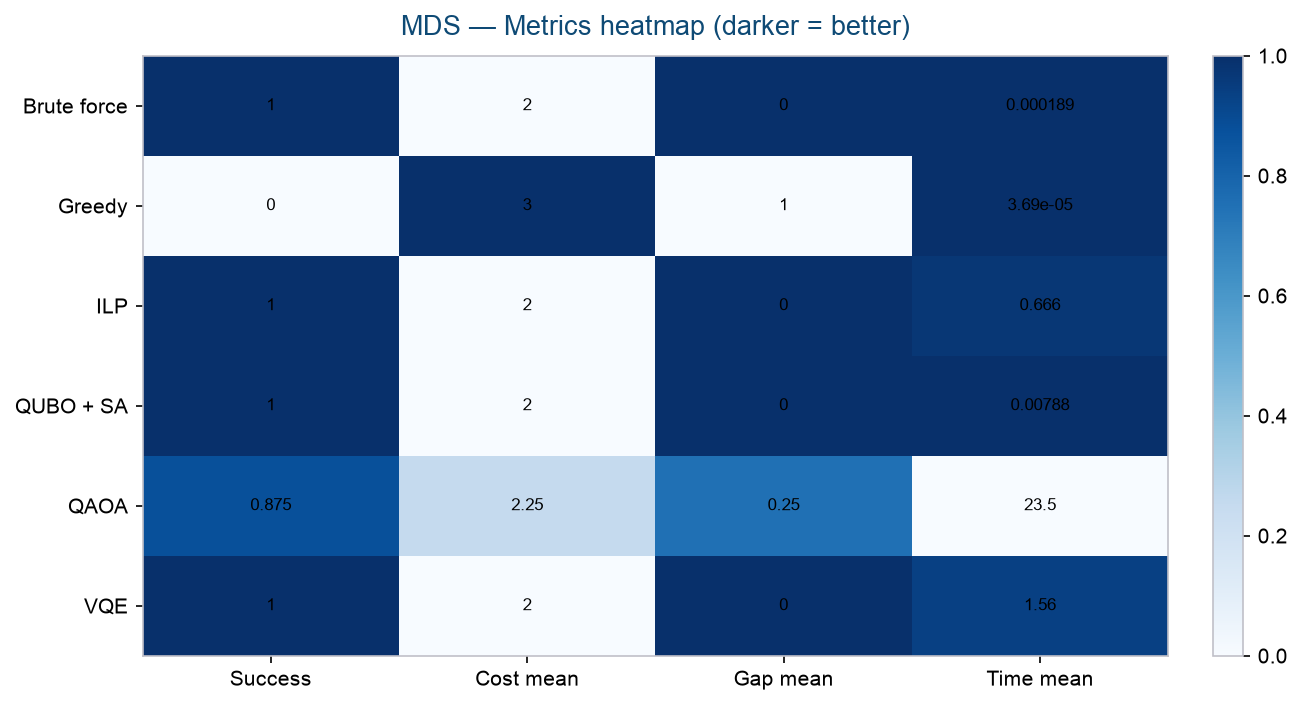

In [11]:
heat_cols = ["success_rate", "cost_mean", "gap_mean", "time_mean_s"]
heat_labels = ["Success", "Cost mean", "Gap mean", "Time mean"]
mat = df.set_index("solver").loc[ALL_SOLVERS, heat_cols]
norm = mat.copy()
for col in heat_cols:
    cmin, cmax = mat[col].min(), mat[col].max()
    if abs(cmax - cmin) < 1e-12:
        norm[col] = 0.5
    elif col in ("gap_mean", "time_mean_s"):
        norm[col] = 1 - (mat[col] - cmin) / (cmax - cmin)
    else:
        norm[col] = (mat[col] - cmin) / (cmax - cmin)

fig, ax = plt.subplots(figsize=(8.8, 4.8))
im = ax.imshow(norm.to_numpy(dtype=float), cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(heat_labels)))
ax.set_xticklabels(heat_labels)
ax.set_yticks(range(len(ALL_SOLVERS)))
ax.set_yticklabels([DISPLAY_NAME[s] for s in ALL_SOLVERS])
ax.set_title("MDS — Metrics heatmap (darker = better)", color=UNIR_NAVY, pad=10)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        ax.text(j, i, f"{mat.iloc[i, j]:.3g}", ha="center", va="center", color="black", fontsize=8)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
savefig("mds_heatmap.png")


## Archivos generados


In [ ]:
print("Summary CSV:")
for p in sorted(SUMMARY_DIR.glob("mds_optimization_summary.csv")):
    print(" -", p)
print("\nFigures:")
for p in sorted(FIGURES_DIR.glob("mds_*.png")):
    print(" -", p)
